# [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/astudentfromsustech/agents-course/blob/main/practice/p2_vit_mnist/vit_mnist.ipynb)

# A transformer that reads handwritten digits

An image is not a sequence. A **Vision Transformer** makes it one: cut the 28x28 image into
7x7 patches, project each to a vector, and call that the sequence. Everything after that is
chapter 01 unchanged — Q/K/V, softmax, multi-head, residual, norm.

The point is not the classifier. It is that three things the chapter *claims* become
**measurable** here:

| | the claim | the measurement |
|---|---|---|
| **position** | attention cannot see order | strip the positional encoding, shuffle the patches: accuracy changes by **exactly +0.00** |
| **scale** | a CNN's locality is a free prior | the gap closes from **-19.4** to **-2.9** as data grows |
| **attention** | the weights are interpretable | the `[CLS]` map runs up the stroke of a `1`, around the ring of a `0` |

Parts 1-3 are what you need to read those three numbers. Part 4 measures them.
Whole notebook ≈ 2 minutes on a GPU.

In [1]:
# Setup — works on Colab and locally, no torchvision needed.
import os, sys, importlib, urllib.request
URL = ("https://raw.githubusercontent.com/astudentfromsustech/agents-course"
       "/main/practice/p2_vit_mnist/vit_mnist.py")
if "google.colab" in sys.modules or not os.path.exists("vit_mnist.py"):
    urllib.request.urlretrieve(URL, "vit_mnist.py")   # on Colab always refetch
import vit_mnist as V
importlib.reload(V)                                   # a warm kernel holds the old module

from IPython.display import Image, display
d = V.load()
print("device:", V.DEV)        # mps = your Mac's GPU | cuda = Colab GPU | cpu = fallback

  MNIST  70,000 images total  =  60,000 train  +  10,000 test
         each (1, 28, 28) — 1 greyscale channel, 28x28 px, labels 0-9
device: mps


---
## 1 · What goes in

**MNIST is 70,000 images: 60,000 train + 10,000 test**, each 28x28 greyscale with a label 0-9.
That split is MNIST's standard one and every number in part 4 respects it — models are fitted on
train images only and scored on the 10,000 test images they never saw. (`exp_scale` varies the
*training* subset — 1,000 / 4,000 / 16,000 / 60,000 — but always scores on the same 10,000.)

28x28 pixels become 16 tokens. This part is only about that step.


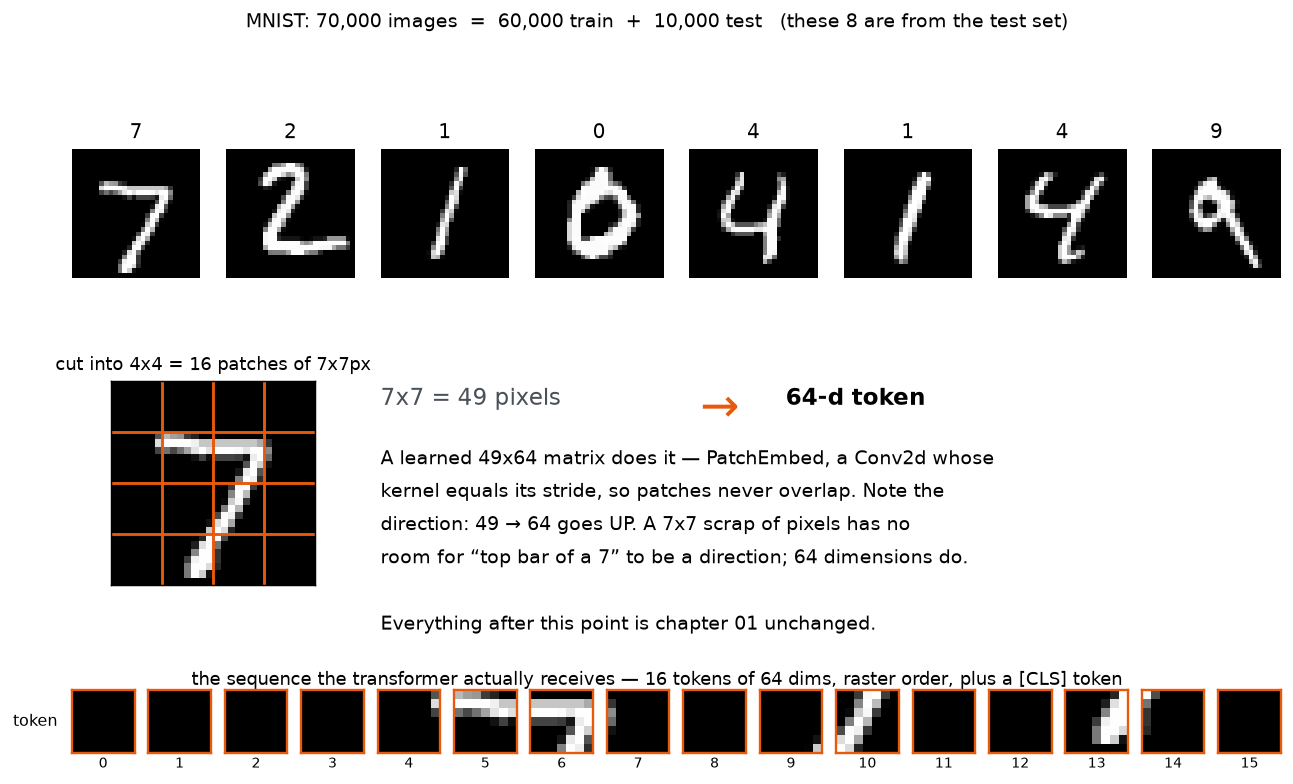

'data_and_patches.png'

In [2]:
V.fold(V.show_data, d, label="▸ the digits, the 7x7 cut, and the 16-token strip")

**The bottom strip is the entire input.** The model never receives the 4x4 arrangement —
only those 16 tokens in order, plus a 17th we will meet shortly. Token 5 and 6 hold the top bar
of the `7`, 10 and 13 the diagonal.

Each token is **64 numbers**, not 49: the patch is 7x7 = 49 pixels, and a learned matrix maps
`49 -> 64`. Here is the real matrix for one digit.


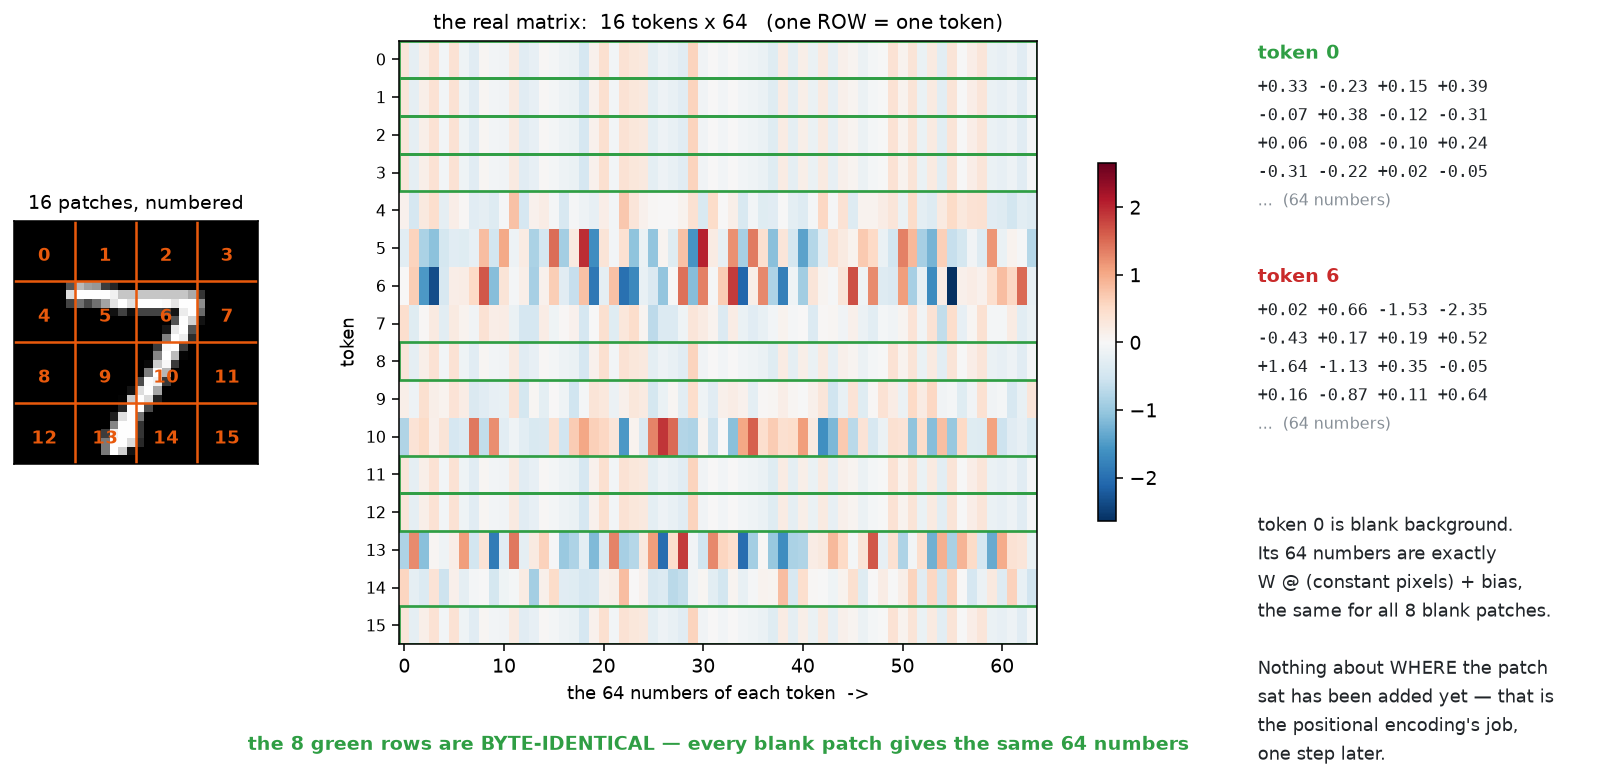

'tokens.png'

In [3]:
V.fold(V.show_tokens, d, label="▸ the real 16 x 64 matrix for one digit")

Rows 5, 6, 10, 13 carry strong values — the inked patches. The eight pale rows outlined in
green are the blank patches, and they are **byte-identical to each other**: a blank patch is 49
copies of the same background value, so its token is `W @ (constant) + bias` wherever it sat.

**So at this point token 0 and token 15 are indistinguishable.** Nothing about *where* a patch
sat has entered yet — which is exactly why experiment 2 comes out the way it does.

### Why 64, when the patch is 49 pixels?

**49 is forced** by the patch size. **64 is chosen** — it is `d_model`, and nothing derives it
from 49. Two questions follow: what is in the extra 15 dimensions, and is `49 -> 64` a real
transformation or just zero-padding?

In [4]:
V.fold(V.why_64, d, label="▸ what is in the extra 15 dimensions")
V.fold(V.is_it_padding, d, label="▸ transformation, or zero-padding?")

tensor([-0.2734,  0.5970, -0.8391, -1.0872, -0.4747, -0.2991, -0.3149, -0.2092,
         0.8181, -0.4964,  0.9961, -0.1311,  0.2203, -0.8463, -0.4653,  1.4869,
        -0.9003,  0.2411,  1.9588, -1.6394,  0.3492, -0.0638,  0.4115, -1.0558,
        -0.1697, -1.0538,  0.0765, -0.3121,  0.7695, -1.5700,  2.0434,  0.2218,
        -0.2176,  1.2190, -0.8737,  1.3674,  0.4303, -1.1048,  0.3218, -0.4568,
        -1.4201, -0.7527, -0.2892,  0.3989,  0.2464,  0.0834,  0.6888,  0.5322,
        -0.1755, -0.4890,  1.3416,  0.8691, -0.8836, -1.2281,  0.6266, -0.6014,
        -0.4715, -0.0933, -0.3319,  1.1746, -0.1860,  0.0904, -0.0250, -0.7634])

**The extra dimensions are empty — for now.** The embedding matrix is `64 x 49`, so its rank
is at most 49, and the singular values of 64,000 real tokens fall off a cliff at exactly index 49.
Every token lives in a 49-dimensional slice of the 64-d space.

They are not waste: `d_model` is the width of the **residual stream for the whole network**, and
every sub-layer *adds* to that stream, so the spare directions are scratch space the blocks write
into. (Three things constrain the choice of 64: it must divide by the head count — you could not
use 49 with 4 heads at all; GPU matmuls like multiples of 8/16/64; and it must be big enough that
`49 -> d` stays injective.)

**And it is a transformation, not padding:** no output equals any pixel, none is zero, and
changing a *single* pixel moves all 64 outputs. `W` is 64 rows of 49 weights — row *j* is a 7x7
filter, and output *j* answers "how much does this patch look like filter *j*?"

> This is not a teaching simplification. `timm` and the paper authors' own JAX code both write
> the same thing — `Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)` then
> `flatten(2).transpose(1,2)` — only with `3 -> 768` at 16x16 instead of `1 -> 64` at 7x7. Their
> comment: *"We can merge s2d+emb into a single conv; it's the same."*

---
## 2 · What the model is


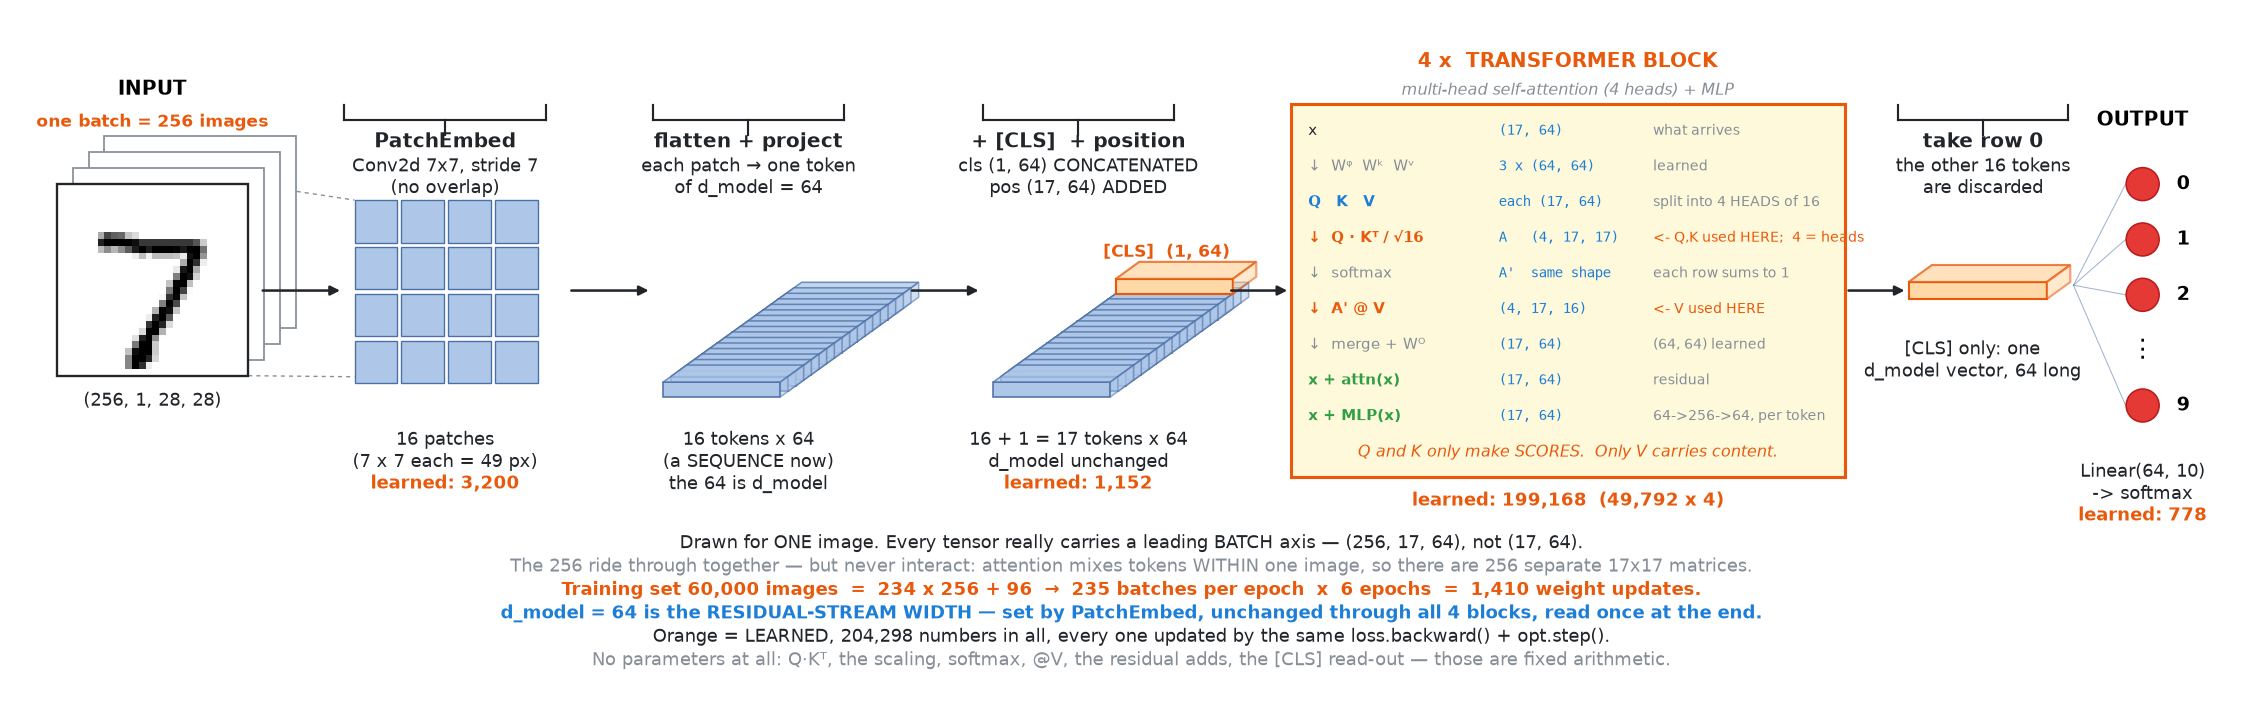

'architecture.png'

In [5]:
V.fold(V.draw_architecture, d, label="▸ the whole model in one picture", start_open=True)

Compare it with the CNN diagrams it imitates. **A CNN's slabs shrink** — 28 to 24 to 12 to
8 to 4 — because every conv and pool trades resolution for channels. **The ViT's slab is
`17 x 64` at the first block and `17 x 64` at the last.** No pooling, no stride, nothing shrinks.
A CNN builds a pyramid; a transformer keeps one fixed workspace and rewrites it in place.

Two things the figure marks that are easy to miss. Every tensor carries a leading **batch** axis
— training is 256 images at a time, 235 batches per epoch, 1,410 weight updates in all. And
**orange = learned**: 204,298 numbers, every one updated by the same `loss.backward()` +
`opt.step()`. `Q·Kᵀ`, the scaling, softmax, `@V` and the residual adds have **no parameters at
all**, which is why the layer's size is independent of sequence length.

If 256 images share a tensor, do they contaminate each other?

In [6]:
V.fold(V.batch_check, d, label="▸ do the 256 images in a batch interact?")

3.8743019104003906e-07

**No** — image 0's logits are the same to `1e-07` whether it travels with 255 companions or
alone, because the attention tensor is 256 *separate* `17x17` matrices and nothing contracts the
batch axis. The one place the batch genuinely combines is the **loss**, which averages over all
256: one gradient, applied once.

Now follow one batch all the way through. Every shape below comes from a live tensor.

In [7]:
V.fold(V.trace_shapes, d, label="▸ one batch, shape by shape")

ViT(
  (patch): PatchEmbed(
    (proj): Conv2d(1, 64, kernel_size=(7, 7), stride=(7, 7))
  )
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (n1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (n2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (qkv): Linear(in_features=64, out_features=192, bias=False)
      (proj): Linear(in_features=64, out_features=64, bias=True)
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=64, bias=True)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=10, bias=True)
)

Four things to notice.

**The image stops being an image on line 3.** `Conv2d` still returns a 4x4 grid; `flatten+transpose`
collapses it to a sequence. After that line the 2-D layout is gone.

**The `17x17` is the whole mechanism** — the only step where information crosses between
positions. LayerNorm, the MLP and every Linear work on one token at a time.

**`(256, 17, 64)` in, `(256, 17, 64)` out, four times.** That invariance is why blocks stack.

**Only `[CLS]` survives.** `t[:, 0]` keeps row 0 and discards 16 tokens — after four layers of
reading them.

### The 4 heads, and what Q, K, V look like

`HEADS = 4`, so each block has 4 heads and the model has 16. The heads **split** the width:
head 0 takes dims 0-15, head 1 takes 16-31, and so on. That is why `d_model` must divide by the
head count — `49/4 = 12.25`, and PyTorch refuses the reshape outright.


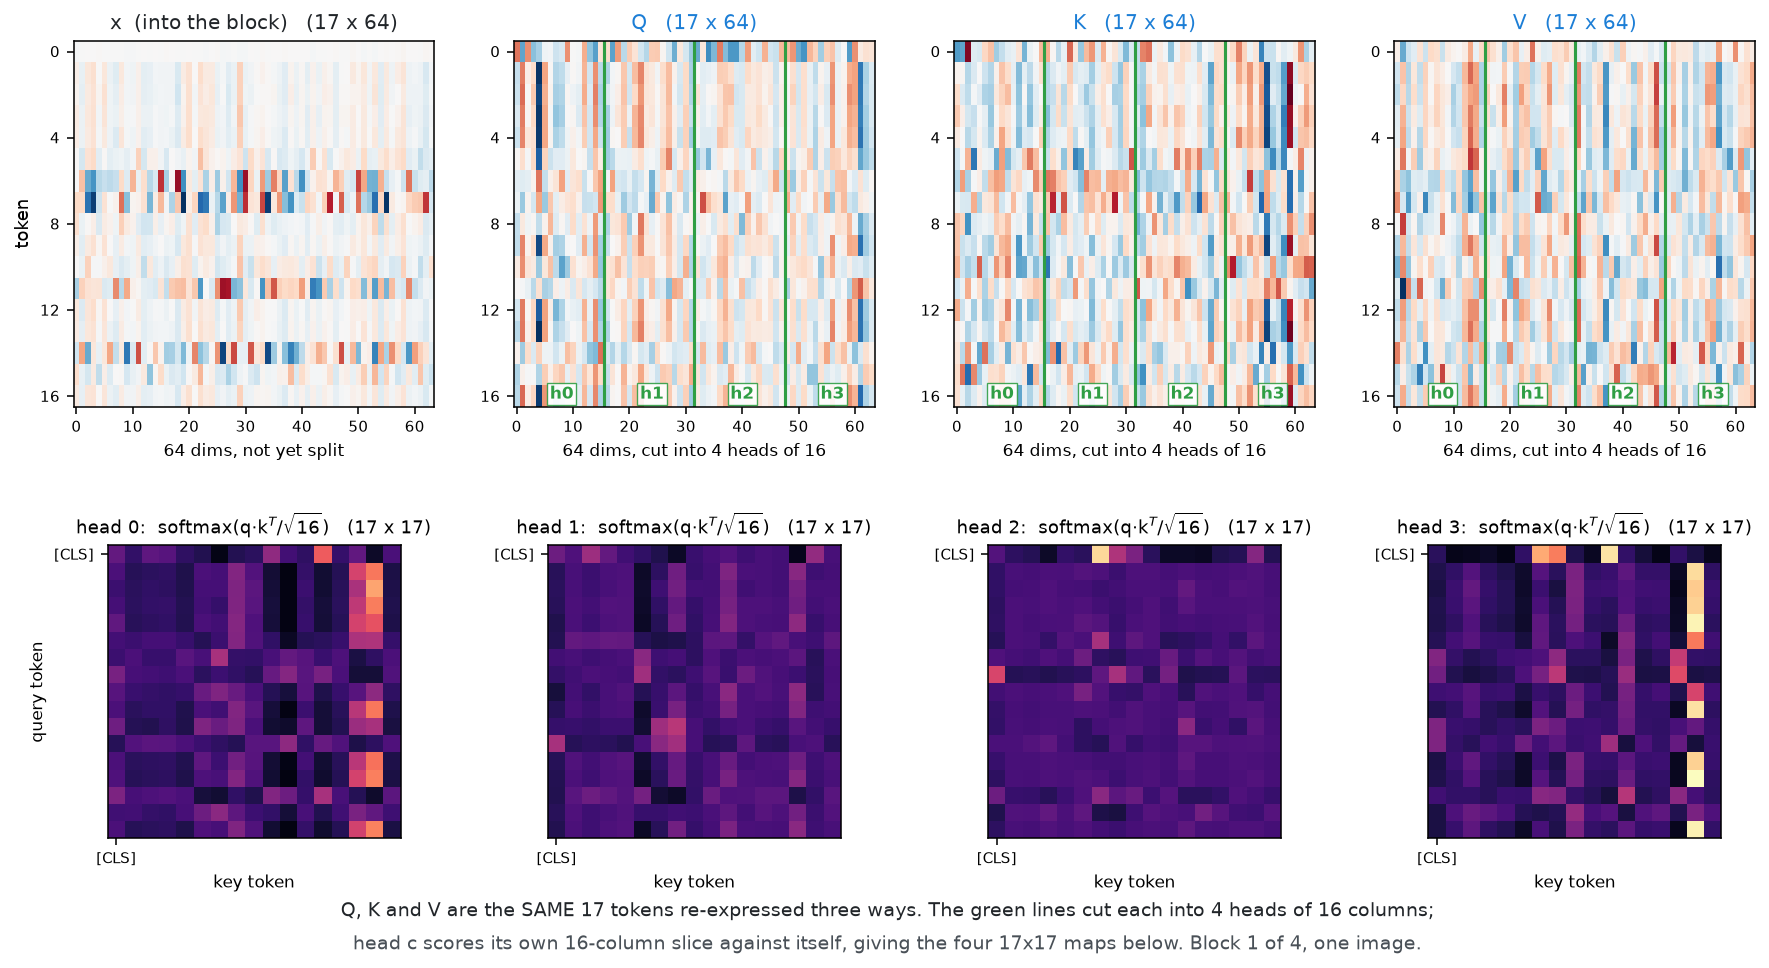

'qkv_heads.png'

In [8]:
V.fold(V.show_qkv, d, label="▸ Q, K, V and the four heads")

**Top row.** `x`, then `Q`, `K`, `V` — three re-expressions of the *same* 17 tokens, each
from its own learned matrix. `x` is visibly banded (rows 5, 6, 10, 13 are the inked patches);
`Q`/`K`/`V` lose that banding because each projection mixes all 64 dimensions.

**Bottom row.** The four `17x17` maps are visibly **different from one another** — head 0
concentrates on a couple of key columns, head 3 has a strong vertical stripe, head 2 is diffuse.
That difference is the entire argument for multi-head.

### `[CLS]` and `position`

Two learned things added at the same step, but in different ways — and the code settles which is
which:

```python
t = torch.cat([self.cls.expand(...), t], 1)   # 16 -> 17   CONCATENATED
t = t + self.pos                              # 17 -> 17   ADDED
```

`position` is a learned `17 x 64` matrix, literally added — **a per-slot bias**. `[CLS]` is a
learned 64-vector concatenated as a **17th token**; CLS is short for *classification*, the token
the classifier reads. It is not a bias: it creates a slot and gets its own q, k, v. Together
64 + 17x64 = **1,152**.

`[CLS]` is 64 ordinary floats, **not a label** — the digits 0-9 appear only as the 10 outputs of
`Linear(64, 10)`. And at the input it is byte-identical for every image. So where do its final
64 floats come from?

**Neither has a closed-form formula** — both are plain learned tensors:

```python
self.cls = nn.Parameter(torch.zeros(1, 1,  64))          # 64 numbers
self.pos = nn.Parameter(torch.randn(1, 17, 64) * 0.02)   # 1,088 numbers
```

So this model does **not** use the sinusoidal `PE(pos,2i) = sin(pos / 10000^(2i/d))` the chapter
derives. ViT and BERT both use a learned table instead, and so does this — position is simply
1,088 more parameters trained by the same loss.

In [9]:
V.fold(V.cls_and_pos, d, label="▸ what [CLS] and position actually are")

tensor([[ 1.0000, -0.1046,  0.0154,  0.2810,  0.1584, -0.3387,  0.0813, -0.2290,
          0.0763, -0.0488,  0.0952,  0.0041,  0.1277,  0.0379, -0.0316,  0.1177],
        [-0.1046,  1.0000,  0.1256, -0.6060, -0.1131, -0.3891,  0.2252, -0.5721,
          0.1026,  0.1027,  0.1192,  0.2410, -0.1174, -0.1174,  0.0414,  0.0828],
        [ 0.0154,  0.1256,  1.0000, -0.0169, -0.3106, -0.3543, -0.3240, -0.3796,
          0.0026,  0.4039,  0.2477,  0.3073,  0.0082, -0.2759, -0.2557, -0.0025],
        [ 0.2810, -0.6060, -0.0169,  1.0000, -0.0337,  0.3267, -0.1708,  0.3352,
         -0.0968, -0.1996, -0.0276, -0.3103,  0.0661,  0.2704,  0.1285,  0.0642],
        [ 0.1584, -0.1131, -0.3106, -0.0337,  1.0000,  0.0491,  0.1559,  0.2717,
         -0.3158, -0.2743,  0.0639, -0.2104,  0.0616, -0.0678,  0.2982, -0.0502],
        [-0.3387, -0.3891, -0.3543,  0.3267,  0.0491,  1.0000, -0.1992,  0.4770,
         -0.1561, -0.3311, -0.2458, -0.3565, -0.1084,  0.1704,  0.2775, -0.1441],
        [ 0.0813,  0.2

In [10]:
V.fold(V.pos_contents, d, label="▸ what is actually IN them — values, ranges, magnitudes")

tensor([[-0.0215, -0.0049,  0.0133,  ..., -0.0003,  0.0372,  0.0296],
        [-0.0442,  0.0112,  0.0473,  ...,  0.0321, -0.0202, -0.0116],
        [-0.0986, -0.0368, -0.0090,  ...,  0.0399,  0.0627,  0.0113],
        ...,
        [-0.0620,  0.0746, -0.0301,  ...,  0.0386,  0.0048, -0.0816],
        [-0.0082,  0.0342, -0.0848,  ...,  0.0081, -0.0649,  0.0224],
        [ 0.0404, -0.0099,  0.0651,  ...,  0.0092, -0.0166,  0.0177]])

Three things in that output.

**`[CLS]` starts at exactly zero and barely moves** — it ends in about ±0.02, `|v| = 0.05`. Its
learned content is nearly irrelevant, which matches the accumulation trace: it enters the stack
at `0.05` and leaves at `7.2`. It is a placeholder that attention fills, so the model has no
reason to make it large.

**Position really is learned** — ±0.3 after training, 3.4x its initialisation.

**And the per-slot magnitudes are not uniform**, which is the interesting part:

| | mean \|pos\| |
|---|---:|
| centre 2x2 | **0.879** |
| edges | 0.408 |
| corners | 0.226 |

The centre is about **4x the corners**. On MNIST the digit sits in the middle, so corner patches
are nearly always blank — and we saw in part 1 that blank patches give **byte-identical** tokens.
Position is the only thing that can distinguish them, and the model spends its magnitude exactly
where distinguishing them changes the answer. Telling one empty corner from another buys nothing.

> Note this corrects the previous cell. There I measured *direction* (cosine between slots) and
> found noise, concluding the table "finds no structure". It does — in **magnitude**. I was
> measuring the wrong axis.

Last number: position is **15% of the content** it is added to (mean `|pos| = 0.48` against mean
`|token| = 3.12`). Big enough to shift a score, small enough not to drown the pixels — which is
why *adding* position works at all rather than swamping the image.

The last table is worth a second look. A **sinusoid is smooth in position by construction** —
`PE(pos+k)` is a fixed rotation of `PE(pos)`, so neighbouring slots come out nearly parallel
(+0.97). A **learned table has no such obligation**, and at this scale it does not find one:
adjacent patches score −0.07, which is noise, not structure.

That is a fact about *this* scale, not a law — large ViTs trained on millions of images do
develop visible 2-D structure in their learned position embeddings. Sixteen slots and 60,000
images is not enough pressure to find it.

And it explains what experiment 2 actually depends on: not that the table is **smooth**, only
that its 17 rows are **distinct**. Distinctness is what breaks permutation equivariance.
Smoothness is a separate benefit, and it only matters when you need to extrapolate to positions
longer than anything seen in training.

In [11]:
V.fold(V.trace_cls, d, label="▸ where [CLS]'s 64 floats come from")

tensor([[ 0.3585,  1.8134, -1.8428,  2.0118, -0.4800,  0.5831,  0.7559, -1.4166,
          1.2103, -0.2722, -1.8823,  1.2967, -1.0552, -1.3363, -0.5525, -0.2903,
          0.0554,  1.3740, -0.5506,  0.9173, -0.0785,  2.0101,  1.0231,  0.0728,
          1.6500,  0.8863, -2.0796,  0.9157,  0.1602,  0.5534, -0.6264,  0.4872,
         -0.0030, -0.5178, -0.0993, -0.5695,  0.2216, -0.9369, -0.7456,  0.8461,
         -0.6903,  0.8056,  0.3967, -1.3898, -0.6004,  2.1065, -1.9904, -1.5081,
         -1.3603,  1.0230,  0.7041,  0.8392,  0.9567,  0.3218, -1.8784, -2.3308,
          0.7258,  0.0232, -1.9559,  0.7960,  1.7474, -0.8308,  0.9087, -0.6810]],
       device='mps:0')

**They are accumulated.** `[CLS]` enters at `|v| = 0.05` with no image content and leaves at
`7.2`, because every sub-layer **adds** rather than replaces — the residual stream. Each of the
64 numbers is a learned constant plus 8 increments.

| | what it adds | can it see other tokens? |
|---|---|---|
| attention | a weighted sum of the 16 patch tokens' values | **yes** — the only step that can |
| MLP | a reshaping of this token alone | no |

So **attention supplies everything that came from the image.** Without it `[CLS]` would finish at
`0.19`, still identical for every image.

---
## 3 · How it learns

Five lines, once per batch:

```python
logits = model(x)                  # guess
loss   = cross_entropy(logits, y)  # how wrong, as ONE number
opt.zero_grad()                    # clear last batch's gradients
loss.backward()                    # d(loss)/d(every one of 204,298 parameters)
opt.step()                         # nudge each parameter downhill
```


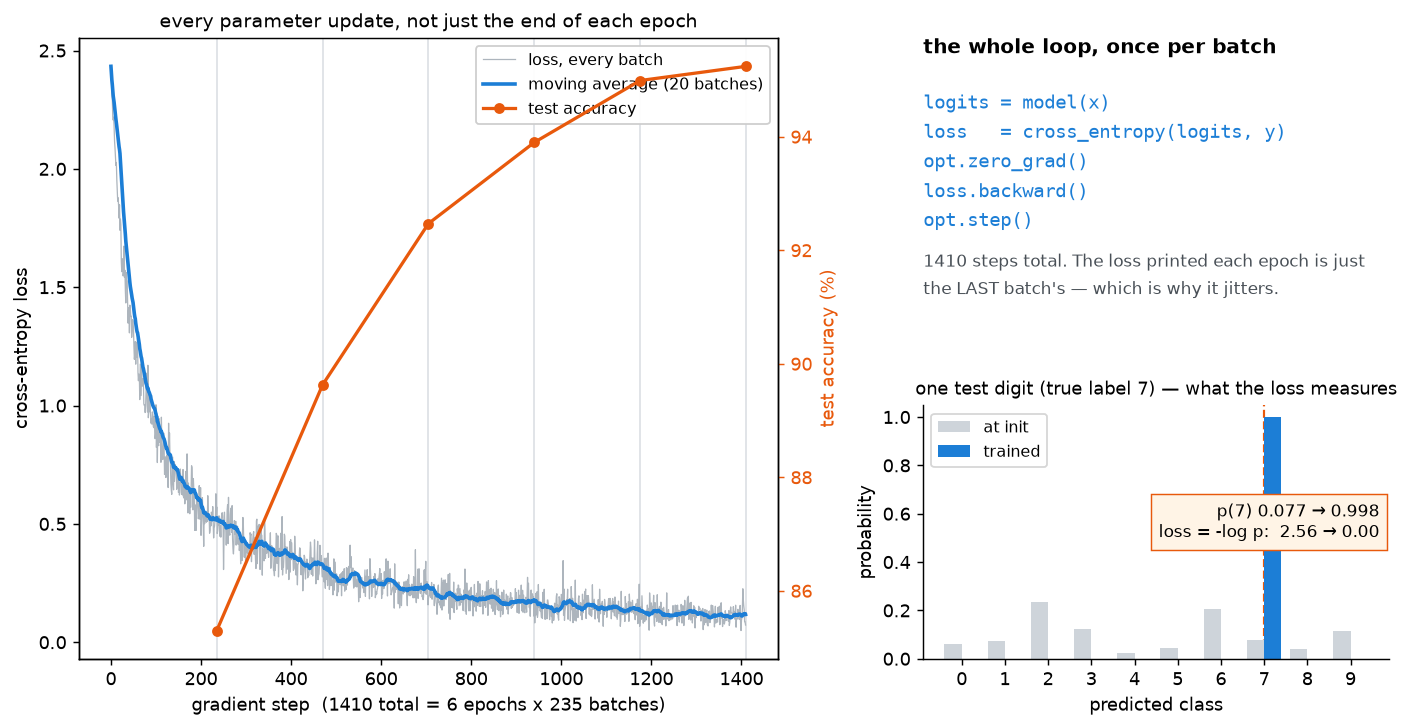

'how_training_works.png'

In [12]:
V.fold(V.show_training, d, label="▸ all 1,410 gradient steps")

**"6 epochs" is 1,410 updates** — 235 batches, six times over. The per-epoch printout samples
a curve doing far more than six things, and the number it prints is the **last batch's** loss,
one of 235 — which is why it jitters, sometimes upward. The blue moving average is the trend.

**Cross-entropy is `-log(probability given to the true class)`.** At init the model spreads
probability over 10 classes, so `-log(0.1) ≈ 2.3` — exactly where the curve starts. Accuracy and
loss ask different questions, which is why the orange curve keeps climbing after the blue one
flattens.

**Do the patch-embedding weights actually move?** Row *j* is a 7x7 filter, so we can look.


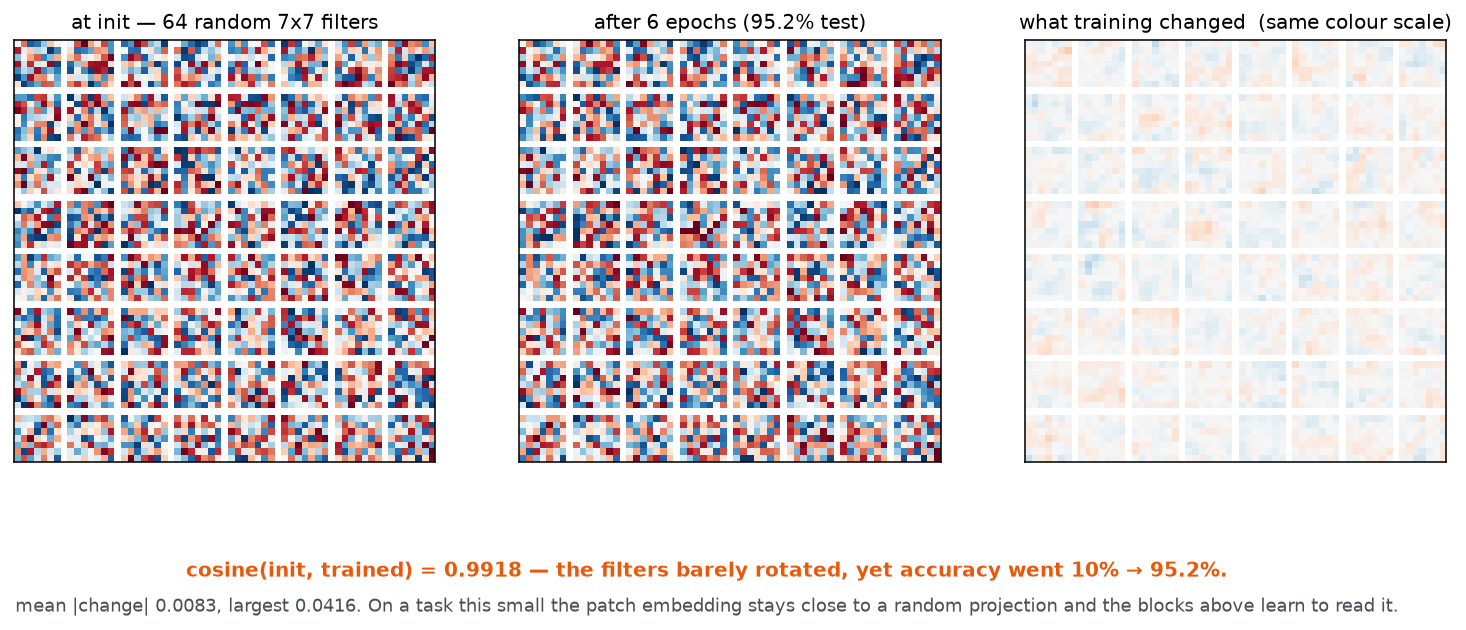

'filters.png'

In [13]:
V.fold(V.show_filters, d, label="▸ the 64 patch filters, before and after")

**Barely.** `cosine(init, trained) ≈ 0.99`, and the third panel — on the same colour scale —
is almost blank. Yet accuracy went 10% to 95%.

On a task this small the patch embedding stays close to a **random projection** and the blocks
above learn to read it. That is a property of *this* setup, not a law: a large ViT's filters move
much further and end up as oriented edge detectors.

It is also the sharpest contrast with word2vec. Word embeddings are usually learned in a
**separate pretraining stage** with their own objective, then handed downstream as a finished
dictionary. A patch embedding has no such stage — pixels are already numeric — so it is learned
end to end from the classification loss, from the position furthest from that loss.

---
## 4 · The three measurements

Everything above was setup. These are the chapter's claims, measured.

### 4.1 It works, and the attention weights are readable

  ViT  204,298 params · 16 patches of 7x7 + 1 CLS = 17 tokens


    epoch 1/6  loss 0.5316  test 85.30%


    epoch 2/6  loss 0.2764  test 89.63%


    epoch 3/6  loss 0.1578  test 92.47%


    epoch 4/6  loss 0.1103  test 93.90%


    epoch 5/6  loss 0.0674  test 94.99%


    epoch 6/6  loss 0.0725  test 95.24%
  final 95.24%  (9s on mps)
  wrote attention_maps.png


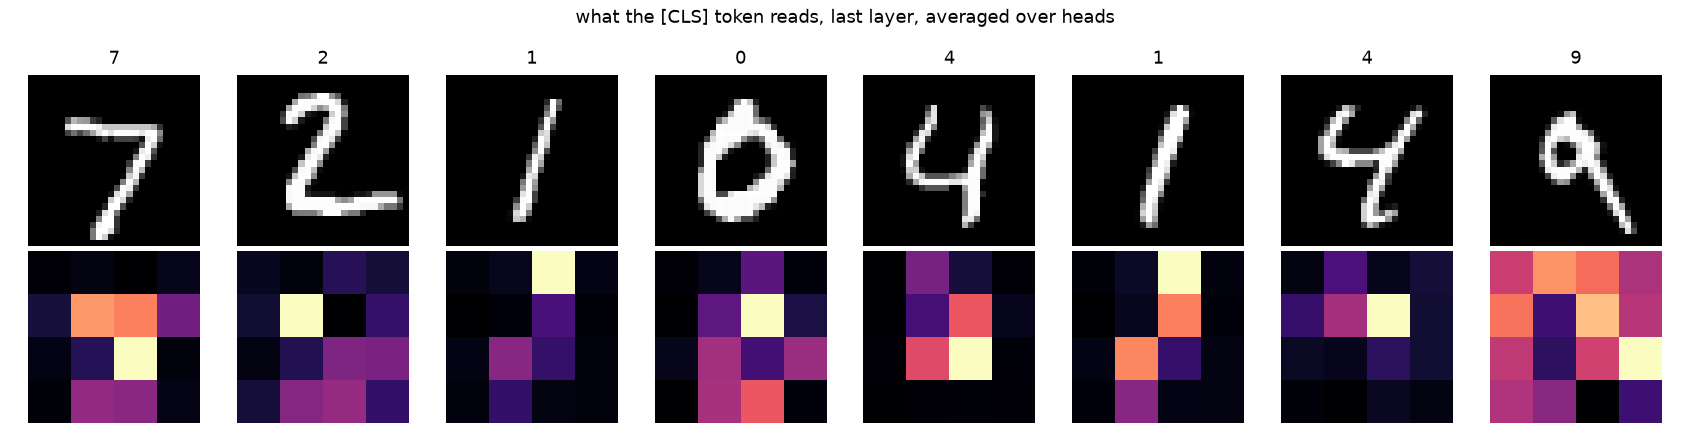

In [14]:
m = V.exp_train(d)
display(Image("attention_maps.png"))

The bottom row is `[CLS]`'s attention over the 4x4 patch grid — **not uniform**. On a `1` the
mass runs up the stroke; on a `0` it sits around the ring. Attention weights are one of the few
interpretable things in a neural network, because they are a distribution over *inputs* rather
than over hidden features.

### 4.2 Position: the one thing attention cannot see

Two identical models, one with the positional encoding switched off, then **shuffle the patch
order at test time**. Predict the four numbers before running it.

In [15]:
rows = V.exp_position(d);

  Training two identical models, one WITHOUT positional encoding.



    pos=True   in order  95.51%   patches shuffled  84.57%   delta -10.94


    pos=False  in order  92.28%   patches shuffled  92.28%   delta  +0.00

  Read the second row: with no positional encoding the shuffle changes
  nothing at all, because the layer never knew the order. That is
  permutation equivariance, measured. The first row is what position buys.


The `+0.00` is the whole point. The model with no positional encoding is not merely *robust*
to the shuffle — it is **incapable of noticing it**, because all it ever received was a set of
vectors like the ones in Part 1, where the blank patches were byte-identical. That is permutation
equivariance, measured. The gap in the first column is what position buys.

### 4.3 Scale: what a prior is worth

Same budget, same gradient steps, growing training set. A CNN has locality **hard-coded**; the
transformer has to learn it.

In [16]:
out = V.exp_scale(d);

  Same budget, same epochs, growing training set.

          N       CNN       ViT   gap


       1000    92.57%    73.20%   -19.37


       4000    94.42%    82.61%   -11.81


      16000    96.45%    87.64%    -8.81


      60000    98.35%    95.47%    -2.88


**Read the gap column, not the accuracy columns.** The CNN's locality prior is free knowledge
handed over before training starts, and it is worth about **19 points at N = 1,000 and 3 points at
N = 60,000**.

No crossover here — the ViT never overtakes the CNN on MNIST, because all of MNIST sits inside the
small-data regime (the crossover in the ViT paper is past 100M images). What a laptop can show is
the **slope**: the prior paying off less and less. That slope is the argument.

---
## Things worth trying

- `V.PATCH = 4` (49 tokens) or `14` (4 tokens) — where does accuracy break, and is the cost
  compute or information?
- `V.LAYERS = 1` — how much does one round of mixing lose?
- `V.D = 32` or `128` — the width-vs-accuracy curve, 13 s per point.
- Shuffle the **pixels inside** each patch instead of the patches. Why does that hurt the
  no-position model, when shuffling patches did not?
- `PatchEmbed` is a `Conv2d` with `kernel_size == stride`. Make them differ so patches overlap —
  you have just reintroduced a locality prior. Does the N = 1,000 number move toward the CNN's?